
## PROJECT 4: Stochastic analysis of an aquifer tracer test
-----

### ABSTRACT


### INTRODUCTION

----------------

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import pandas as pd
from scipy.optimize import least_squares

In [2]:
rng = np.random.default_rng()

In [ ]:
class Solver:
    def __init__(self, x0, t0, v=0.5, D=1, alpha_L=2, lamb=0.002, M=1000, L1=50, L2=500):
        self.x0 = x0
        self.t0 = t0
        self.v = v
        self.D = D
        self.alpha_L = alpha_L
        self.lamb = lamb
        self.M = M
        self.L1 = L1
        self.L2 = L2

    def random_walk_1d(self, dt, number_of_steps, N = 20000, decay=True):
        p_decay = 1 - np.exp(-self.lamb*dt)

        trajectories = np.zeros((N, number_of_steps + 1))
        trajectories[:, 0] = self.x0
        alive = np.ones(N, dtype=bool)

        # checkpoint
        alive_count = np.zeros(number_of_steps + 1, dtype=int)
        alive_count[0] = N

        for i in range(number_of_steps):
            random_steps = np.random.normal(0, 1, N)
            trajectories[alive, i+1] = (trajectories[alive, i] + self.v * dt + np.sqrt(2 * self.D * dt) * random_steps[alive])

            if decay:
                decay_events = np.random.random(N) < p_decay
                alive = alive & ~decay_events
            
            trajectories[~alive, i+1] = np.nan

            alive_count[i+1] = np.sum(alive)
            
        return trajectories, alive_count

    def concentration_profile(self, trajectories, N, dt, time_points, bins=100, x_range=(0, 500)):
        profiles = {}

        bin_edges = np.linspace(x_range[0], x_range[1], bins+1)
        bin_centers = (bin_edges[:-1]  + bin_edges[1:]) / 2
        bin_width = bin_edges[1] - bin_edges[0]

        for t in time_points:
            step = int(t/dt)
            positions = trajectories[:, step]
            positions = positions[~np.isnan(positions)]

            counts, _ = np.histogram(positions, bins=bin_edges)

            C = (self.M/N) * counts / bin_width
            profiles[t] = C

        return bin_centers, profiles

    def concentration_ananlytical(self, x, t):
        C = (self.M / np.sqrt(4*np.pi*self.D*t)) * np.exp(-((x - self.v*t)**2)/(4*self.D*t) - self.lamb*t)
        return C

    def first_arrival_times(self, trajectories, dt):
        L1 = self.L1

        previous = trajectories[:, :-1]
        current = trajectories[:, 1:]

        crossed = (previous < L1) & (current > L1)
        arrived = np.any(crossed, axis=1)
        first_cross = np.argmax(crossed, axis=1)

        arrival_times = np.full(trajectories.shape[0], np.nan)
        arrival_times[arrived] = (first_cross[arrived] + 1) * dt

        return arrival_times

    def first_arrival_analytical(self, t):
        L1 = self.L1
        f = L1/(np.sqrt(4*np.pi*self.D*t**3)) * np.exp(-((L1-self.v*t)**2)/(4*self.D*t))
        return f

    def concentration_tracer(self, L1, t, theta):
        f1, f2, v1, v2, v3, alpha_L = theta
        f3 = 1-f1-f2
        f = [f1, f2, f3]
        v = [v1, v2, v3]

        C = 0
        for i in range(3):
            sum = (f[i] * self.M / np.sqrt(4 *np.pi * alpha_L * v[i] *t) * np.exp(-(L1 - v[i] * t)**2 / (4 * alpha_L * v[i] * t)))
            C += sum

        return C

    def misfit(self, L1, t_data, theta, sigma, C_obs):

        C_tracer = np.array([self.concentration_tracer(L1, t, theta) for t in t_data])
        J = (1 / (2 * sigma**2)) * np.sum((C_tracer - C_obs)**2)
        
        return J

    def local_opt(self, L1, t_data, theta_init, sigma, C_obs):

        def residuals(x):
            a, b, v1, v2, v3, alpha_L = x
            f1 = a
            f2 = (1 - a) * b

            theta = [f1, f2, v1, v2, v3, alpha_L]
            C_tracer = np.array([
                self.concentration_tracer(L1, t, theta)
                for t in t_data
            ])

            return (C_tracer - C_obs) / sigma

        f1, f2, v1, v2, v3, alpha_L = theta_init
        a = f1
        b = f2 / (1 - f1) if f1 < 1 else 0
        x0 = [a, b, v1, v2, v3, alpha_L]
        lower = [0, 0, 0.1, 0.1, 0.1, 0.05]
        upper = [1, 1, 2, 2, 2, 5]

        opt = least_squares(residuals,x0,bounds=(lower, upper))
        a, b, v1, v2, v3, alpha_L = opt.x
        f1 = a
        f2 = (1-a)*b
        theta_opt = [f1,f2,v1,v2,v3,alpha_L]

        return theta_opt

    def multi_start(self, L1, t_data, sigma, C_obs):
        results = []
        for i in range(40):
            f1 = rng.uniform(0, 1)
            f2 = rng.uniform(0, 1-f1)
            v1 = rng.uniform(0.1, 2)
            v2 = rng.uniform(0.1, 2)
            v3 = rng.uniform(0.1, 2)
            alpha_L = rng.uniform(0.05, 5)
            theta_init = [f1, f2, v1, v2, v3, alpha_L]

            theta_opt = self.local_opt(L1, t_data, theta_init, sigma, C_obs)
            J = self.misfit(L1, t_data, theta_opt, sigma, C_obs)
            results.append((theta_opt, J))

        return results

    def simulated_annealing(self, f, x0, bounds, T0=1000, T_min=0.5, tau=0.95, steps_per_T=100, proposal_width=0.1):
        
        x = np.array(x0, dtype=float)
        f_x = f(x)
        lower, upper = np.array(bounds[0]), np.array(bounds[1])
        best_x = x.copy()
        best_f = f_x
        T = T0
        k = 0
        proposal_width = 0.1 * (upper - lower)
        trace_x = [x.copy()]
        trace_f = [f_x]

        while T>T_min:
            for _ in range(steps_per_T):
                sigma = proposal_width * np.sqrt(T / T0)
                x_new = x + rng.normal(0, sigma)

                if np.any(x_new < lower) or np.any(x_new > upper):
                    trace_x.append(x.copy())
                    trace_f.append(f_x)
                    continue

                f_new = f(x_new)
                dE = f_new - f_x

                if dE < 0 or rng.random() < np.exp(-dE/T):
                    x, f_x = x_new, f_new

                if f_x < best_f:
                    best_x, best_f = x.copy(), f_x 

                trace_x.append(x.copy())
                trace_f.append(f_x)

            k += 1
            T = T0 * np.exp(-k/tau)

        return {
        "best_x": best_x,
        "best_f": best_f,
        "trace_x": np.array(trace_x),
        "trace_f": np.array(trace_f)
    }

In [5]:
def plot_particle_position(trajectories, dt, times=[40, 120, 300]):

    plt.figure(figsize=(10, 5))

    colors = ['tab:blue', 'tab:orange', 'tab:green']

    for t, color in zip(times, colors):

        step = int(t / dt)
        positions = trajectories[:, step]

        positions = positions[~np.isnan(positions)]
        y = np.random.uniform(0, 1, len(positions))

        plt.scatter(
            positions,
            y,
            s=2,
            alpha=0.4,
            color=color,
            label=f't = {t} days'
        )

    plt.axvline(50, color='red', linestyle='--')

    plt.xlabel('x [m]')
    plt.legend()
    plt.tight_layout()
    plt.show()

Initial number of particles: 20000
Surviving particles: 11132
Decayed particles: 8868
Percentage decayed: 44.34%


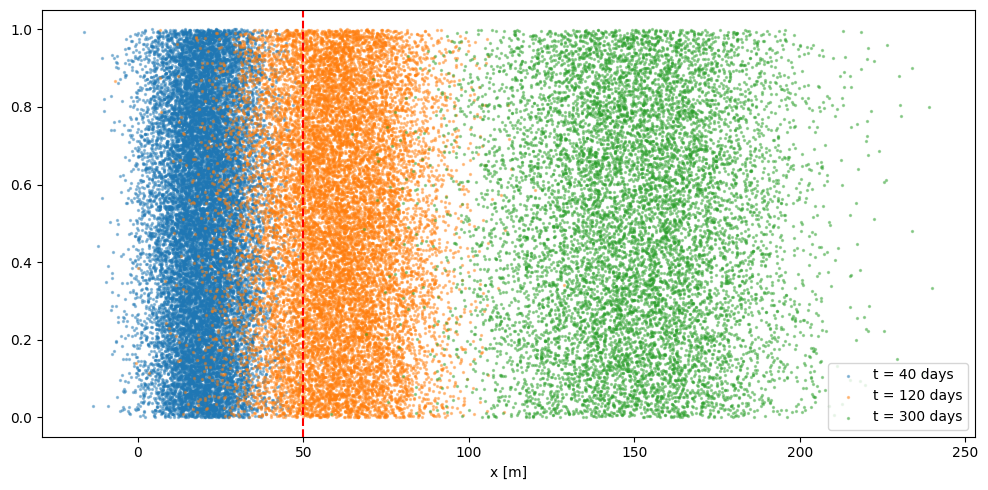

In [6]:
dt = 0.5
number_of_steps = 600  # 300 days
N = 20000

solver = Solver(x0=0, t0=0)

trajectories, alive_count = solver.random_walk_1d(
    dt=dt,
    number_of_steps=number_of_steps,
    N=N
)

print(f"Initial number of particles: {N}")
print(f"Surviving particles: {alive_count[-1]}")
print(f"Decayed particles: {N - alive_count[-1]}")
print(f"Percentage decayed: {(N - alive_count[-1]) / N * 100:.2f}%")

plot_particle_position(trajectories, dt)

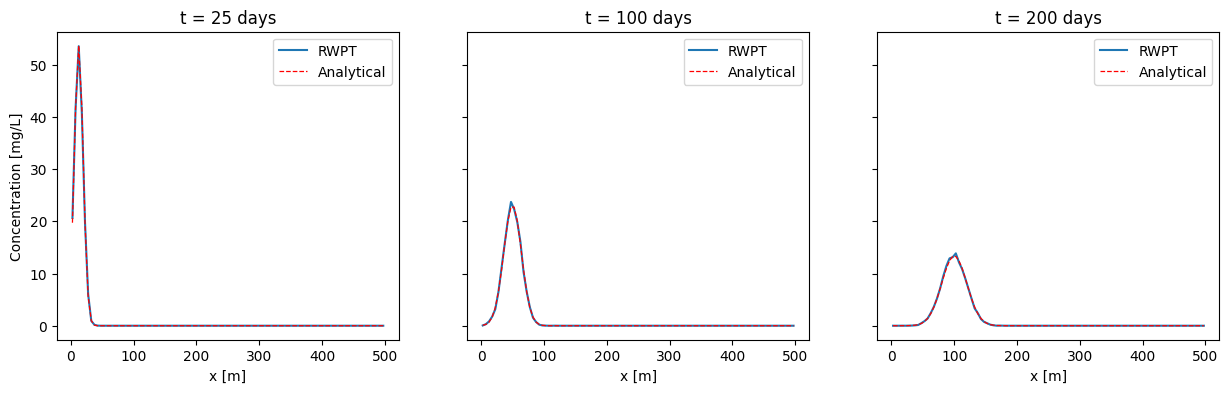

In [7]:
time_points = [25, 100, 200]

x, profiles = solver.concentration_profile(
    trajectories=trajectories,
    N=N,
    dt=dt,
    time_points=time_points,
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, t in zip(axes,time_points):
    ax.plot(x, profiles[t], label="RWPT", color="tab:blue")

    C_analytical = solver.concentration_ananlytical(x, t)
    ax.plot(x, C_analytical, "--", linewidth=0.9, label="Analytical", color="red")

    ax.set_title(f"t = {t} days")
    ax.set_xlabel("x [m]")
    ax.legend()

axes[0].set_ylabel("Concentration [mg/L]")
plt.show()

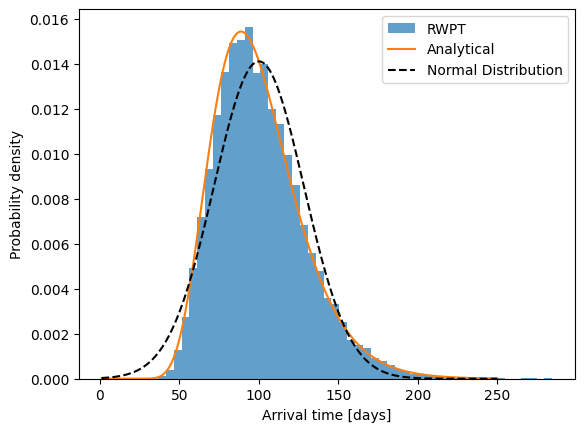

In [8]:
trajectories_no_decay, _ = solver.random_walk_1d(dt=0.5, number_of_steps=600, N=20000, decay=False)

arrival_times = solver.first_arrival_times(trajectories_no_decay, dt)
valid_arrivals = arrival_times[~np.isnan(arrival_times)]

t = np.linspace(1, 250, 1000)
f_analytical = solver.first_arrival_analytical(t)

mean = solver.L1 / solver.v
variance = 2 * solver.D * solver.L1 / solver.v**3
std = np.sqrt(variance)
normal_distribution = norm.pdf(t, mean, std)

plt.figure()
plt.hist(valid_arrivals, bins=50, density=True, alpha=0.7, label="RWPT")
plt.plot(t, f_analytical, label="Analytical")
plt.plot(t, normal_distribution, linestyle='--', color="black", label="Normal Distribution")
plt.xlabel("Arrival time [days]")
plt.ylabel("Probability density")
plt.legend()
plt.show()

TO DO:  Is the arrival time normally distributed? Explain.

## PART 3

In [49]:
tracer_test = pd.read_csv("tracer_test.csv")
tracer_test.head()

,time_days,concentration_mg_per_L
0,5.0,6.1228
1,10.0,-7.6670
2,15.0,1.2543
3,20.0,-1.7033
4,25.0,-1.3577


In [50]:
# initiating the parameters needed to run the misfit function

L1 = 50
t_data = tracer_test["time_days"]
sigma = 3
C_obs = tracer_test["concentration_mg_per_L"]

solver = Solver(x0=0, t0=0)
# we call on the function multi_start, which computes J from 40 different starting points
results = solver.multi_start(L1, t_data, sigma, C_obs)

In [ ]:
best_theta, best_J = min(results, key=lambda x: x[1])

f1, f2, v1, v2, v3, alpha_L = best_theta
f3 = 1 - f1 - f2

print(f"Global minimum misfit: J = {best_J:.6f}")

print("Best parameters:")
print(f"f1 = {f1:.4f}")
print(f"f2 = {f2:.4f}")
print(f"f3 = {f3:.4f}")
print(f"v1 = {v1:.4f}")
print(f"v2 = {v2:.4f}")
print(f"v3 = {v3:.4f}")
print(f"alpha_L = {alpha_L:.4f}")
print(f"Misfit = {best_J:.4f}")

Global minimum misfit: J = 29.780056
Best parameters:
f1 = 0.1993
f2 = 0.2967
f3 = 0.5040
v1 = 1.1154
v2 = 0.5904
v3 = 0.3018
alpha_L = 0.2996
Misfit = 29.7801

All 40 misfit values:
Run 1: J = 128.519559
Run 2: J = 29.780056
Run 3: J = 67.932281
Run 4: J = 29.780056
Run 5: J = 67.932281
Run 6: J = 67.932281
Run 7: J = 29.780056
Run 8: J = 29.780056
Run 9: J = 128.519559
Run 10: J = 64.835989
Run 11: J = 29.780056
Run 12: J = 29.780056
Run 13: J = 67.932281
Run 14: J = 112.351994
Run 15: J = 64.835989
Run 16: J = 29.780056
Run 17: J = 29.780056
Run 18: J = 67.932281
Run 19: J = 29.780056
Run 20: J = 29.780056
Run 21: J = 29.780056
Run 22: J = 29.780056
Run 23: J = 29.780056
Run 24: J = 48.175181
Run 25: J = 29.780056
Run 26: J = 48.175181
Run 27: J = 29.780056
Run 28: J = 29.780056
Run 29: J = 67.932281
Run 30: J = 29.780056
Run 31: J = 29.780056
Run 32: J = 29.780056
Run 33: J = 29.780056
Run 34: J = 29.780056
Run 35: J = 67.932281
Run 36: J = 29.780056
Run 37: J = 29.780056
Run 38: J

In [64]:
print("All 40 misfit values:")

min_runs = 0

for i, result in enumerate(results):
    if abs(result[1] - best_J) < 1e-5:
        min_runs +=1

    print(f"Run {i+1}: J = {result[1]:.6f}")

print("\nFraction of runs with minimalized J:", min_runs/ len(results))

All 40 misfit values:
Run 1: J = 128.519559
Run 2: J = 29.780056
Run 3: J = 67.932281
Run 4: J = 29.780056
Run 5: J = 67.932281
Run 6: J = 67.932281
Run 7: J = 29.780056
Run 8: J = 29.780056
Run 9: J = 128.519559
Run 10: J = 64.835989
Run 11: J = 29.780056
Run 12: J = 29.780056
Run 13: J = 67.932281
Run 14: J = 112.351994
Run 15: J = 64.835989
Run 16: J = 29.780056
Run 17: J = 29.780056
Run 18: J = 67.932281
Run 19: J = 29.780056
Run 20: J = 29.780056
Run 21: J = 29.780056
Run 22: J = 29.780056
Run 23: J = 29.780056
Run 24: J = 48.175181
Run 25: J = 29.780056
Run 26: J = 48.175181
Run 27: J = 29.780056
Run 28: J = 29.780056
Run 29: J = 67.932281
Run 30: J = 29.780056
Run 31: J = 29.780056
Run 32: J = 29.780056
Run 33: J = 29.780056
Run 34: J = 29.780056
Run 35: J = 67.932281
Run 36: J = 29.780056
Run 37: J = 29.780056
Run 38: J = 29.780056
Run 39: J = 29.780056
Run 40: J = 29.780056

Fraction of runs with minimalized J: 0.65


In [56]:
local_theta, local_J = max(results, key=lambda x: x[1])

print(f"Local minimum misfit: J = {local_J:.6f}")

f1, f2, v1, v2, v3, alpha_L = local_theta
f3 = 1 - f1 - f2

print("Worst parameters:")
print(f"f1 = {f1:.4f}")
print(f"f2 = {f2:.4f}")
print(f"f3 = {f3:.4f}")
print(f"v1 = {v1:.4f}")
print(f"v2 = {v2:.4f}")
print(f"v3 = {v3:.4f}")
print(f"alpha_L = {alpha_L:.4f}")
print(f"Misfit = {local_J:.4f}")

Local minimum misfit: J = 128.519559
Worst parameters:
f1 = 0.1450
f2 = 0.5520
f3 = 0.3030
v1 = 2.0000
v2 = 0.3022
v3 = 1.1206
alpha_L = 0.3623
Misfit = 128.5196


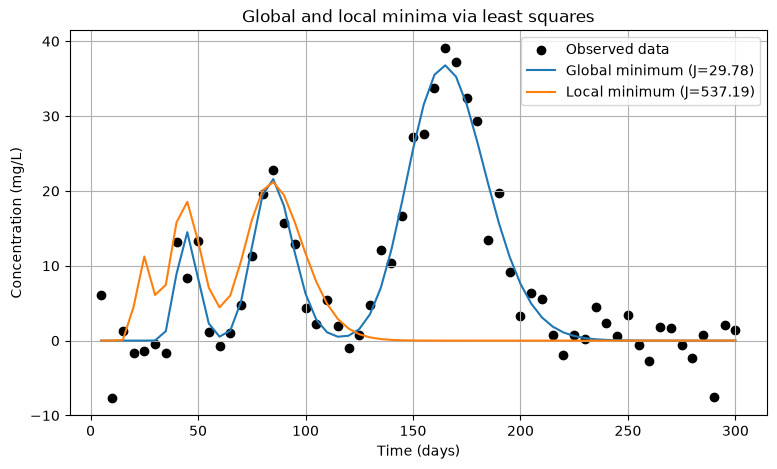

In [42]:
C_global = np.array([
    solver.concentration_tracer(L1, t, best_theta)
    for t in t_data
])

C_local = np.array([
    solver.concentration_tracer(L1, t, local_theta)
    for t in t_data
])

plt.figure(figsize=(9, 5))
plt.scatter(t_data, C_obs, color='black', label='Observed data')
plt.plot(t_data, C_global, label=f'Global minimum (J={best_J:.2f})')
plt.plot(t_data, C_local, label=f'Local minimum (J={local_J:.2f})')

plt.xlabel('Time (days)')
plt.ylabel('Concentration (mg/L)')
plt.title('Global and local minima via least squares')
plt.legend()
plt.grid()
plt.show()

------
### SIMULATED ANNEALING

In [7]:
# initiating theta bounds and inital theta guesses needed for SA

lower = np.array([0, 0, 0.1, 0.1, 0.1, 0.05])
upper = np.array([1, 1, 2, 2, 2, 5])
bounds = (lower, upper)

a = rng.uniform(0, 1)
b = rng.uniform(0, 1)
v1 = rng.uniform(0.1, 2)
v2 = rng.uniform(0.1, 2)
v3 = rng.uniform(0.1, 2)
alpha_L = rng.uniform(0.05, 5)

theta_init = np.array([a, b, v1, v2, v3, alpha_L])

In [8]:
def objective_sa(x):
    a, b, v1, v2, v3, alpha_L = x
    f1 = a
    f2 = (1-a)*b
    theta = [f1, f2, v1, v2, v3, alpha_L]

    return solver.misfit(L1, t_data, theta, sigma, C_obs)

In [66]:
tau_values = [25, 50, 75, 100]
n_runs = 20
results = {}

absolute_best_f = np.inf
absolute_best_x = None
absolute_best_tau = None

for tau in tau_values:
    best_misfits = []

    for i in range(n_runs):

        theta_init = np.array([
            rng.uniform(0, 1),
            rng.uniform(0, 1),
            rng.uniform(0.1, 2),
            rng.uniform(0.1, 2),
            rng.uniform(0.1, 2),
            rng.uniform(0.05, 5)
        ])

        SA = solver.simulated_annealing(
            f=objective_sa,
            x0=theta_init,
            bounds=bounds,
            T0=1000,
            T_min=0.5,
            tau=tau,
            steps_per_T=20
        )

        best_misfits.append(SA["best_f"])

        if SA["best_f"] < absolute_best_f:

            absolute_best_f = SA["best_f"]
            absolute_best_x = SA["best_x"].copy()
            absolute_best_tau = tau

    results[tau] = best_misfits

    print(f"Tau = {tau}")
    print(f"Best misfit: {np.min(best_misfits):.4f}")
    print(f"Mean misfit: {np.mean(best_misfits):.4f}")
    print(f"Std misfit: {np.std(best_misfits):.4f}")
    print(f"\n")

print('-'*50)
print("BEST RUN:")

print("Best tau:", absolute_best_tau)
print("Best misfit:", absolute_best_f)

a, b, v1, v2, v3, alpha_L = absolute_best_x
f1 = a
f2 = (1-a)*b
f3 = (1-a)*(1-b)
theta_best = [f1, f2, v1, v2, v3, alpha_L]

print("\nBest parameters:")
print("f1:", f1)
print("f2:", f2)
print("f3:", f3)
print("Sum of fractions:", f1+f2+f3)
print("v1:", v1)
print("v2:", v2)
print("v3:", v3)
print("alpha_L:", alpha_L)

Tau = 25
Best misfit: 29.9018
Mean misfit: 95.0728
Std misfit: 66.3284


Tau = 50
Best misfit: 29.8660
Mean misfit: 39.8036
Std misfit: 15.6680


Tau = 75
Best misfit: 29.8503
Mean misfit: 48.2201
Std misfit: 24.6474


Tau = 100
Best misfit: 29.9326
Mean misfit: 41.4855
Std misfit: 23.8100


--------------------------------------------------
BEST RUN:
Best tau: 75
Best misfit: 29.850320216922416

Best parameters:
f1: 0.5014877292406761
f2: 0.2017283479685347
f3: 0.29678392279078925
Sum of fractions: 1.0
v1: 0.3018715663809696
v2: 1.1205174427013573
v3: 0.5918452445153516
alpha_L: 0.30243203024614945


In [25]:
C_computed = np.array([solver.concentration_tracer(L1, t, theta_best) for t in t_data])
C_computed

array([2.72136898e-130, 1.24307358e-049, 4.07292978e-024, 2.23460671e-012,
       3.81797226e-006, 1.15608665e-002, 9.39569661e-001, 7.97094567e+000,
       1.50067626e+001, 9.85628439e+000, 3.02034344e+000, 6.81087876e-001,
       1.30902444e+000, 5.04187682e+000, 1.20807973e+001, 1.90257016e+001,
       2.11957851e+001, 1.76976418e+001, 1.15918653e+001, 6.17816411e+000,
       2.76487083e+000, 1.09252974e+000, 5.05775218e-001, 6.23517661e-001,
       1.48206464e+000, 3.42635883e+000, 6.87246319e+000, 1.19941937e+001,
       1.84550332e+001, 2.53491133e+001, 3.14257916e+001, 3.55030565e+001,
       3.68617091e+001, 3.54370045e+001, 3.17527361e+001, 2.66746935e+001,
       2.11196764e+001, 1.58336217e+001, 1.12876905e+001, 7.68078346e+000,
       5.00569956e+000, 3.13418536e+000, 1.89061046e+000, 1.10154693e+000,
       6.21348372e-001, 3.40030956e-001, 1.80881603e-001, 9.36988571e-002,
       4.73419777e-002, 2.33658842e-002, 1.12808574e-002, 5.33433339e-003,
       2.47348100e-003, 1

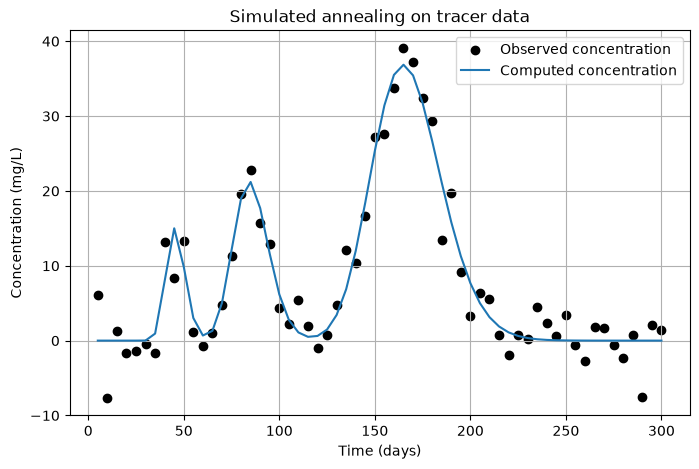

In [30]:
plt.figure(figsize=(8,5))
plt.scatter(t_data, C_obs, color = 'black', label="Observed concentration")
plt.plot(t_data, C_computed, label="Computed concentration")
plt.xlabel("Time (days)")
plt.ylabel("Concentration (mg/L)")
plt.title("Simulated annealing on tracer data")
plt.legend()
plt.grid()
plt.show()